<a href="https://colab.research.google.com/github/vaideheedaf/ML-Coral-reef/blob/main/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay, roc_curve
)
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
TRAIN_PATH = "ML_train.csv"
VALID_PATH = "ML_valid.csv"
TEST_PATH = "ML_test.csv"

In [ ]:
# Load the three supplied datasets
train_df = pd.read_csv("/content/ML_train.csv")
valid_df = pd.read_csv("/content/ML_valid.csv")
test_df = pd.read_csv("/content/ML_test.csv")

Train shape: (9662, 12)
Validation shape: (463, 12)
Test shape: (257, 12)

Target distribution:
TRAIN
 target
Bleached    4980
Healthy     4682
Name: count, dtype: int64

VALID
 target
Bleached    240
Healthy     223
Name: count, dtype: int64

TEST
 target
Bleached    135
Healthy     122
Name: count, dtype: int64


In [ ]:
FEATURES = [
    "mean_saturation",
    "mean_brightness",
    "white_pixel_pct",
    "mean_lightness",
    "lbp_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "edge_density",
    "entropy",
]
TARGET = "target"
LABELS = ["Bleached", "Healthy"]

train: missing feature values = 0
train: infinite feature values = 0
valid: missing feature values = 0
valid: infinite feature values = 0
test: missing feature values = 0
test: infinite feature values = 0

Using features: ['mean_saturation', 'mean_brightness', 'white_pixel_pct', 'mean_lightness', 'lbp_mean', 'glcm_contrast', 'glcm_homogeneity', 'edge_density', 'entropy']
Target labels: ['Bleached', 'Healthy']


In [ ]:
# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_imp, y_train)

print("Random Forest training completed successfully.")
print("Number of trees:", rf.n_estimators)
print("Training accuracy:", round(accuracy_score(y_train, rf.predict(X_train_imp)), 4))

Random Forest training completed successfully.
Number of trees: 500
Training accuracy: 1.0


In [ ]:
# Validation evaluation
valid_pred = rf.predict(X_valid_imp)

print("VALIDATION RESULTS")
print("Accuracy :", round(accuracy_score(y_valid, valid_pred), 4))
print("Precision:", round(precision_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))
print("Recall   :", round(recall_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))
print("F1-score :", round(f1_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))

VALIDATION RESULTS
Accuracy : 0.9503
Precision: 0.9502
Recall   : 0.9542
F1-score : 0.9522

Classification report:

              precision    recall  f1-score   support

    Bleached       0.95      0.95      0.95       240
     Healthy       0.95      0.95      0.95       223

    accuracy                           0.95       463
   macro avg       0.95      0.95      0.95       463
weighted avg       0.95      0.95      0.95       463



Validation confusion matrix (rows = actual, columns = predicted):
[[229  11]
 [ 12 211]]


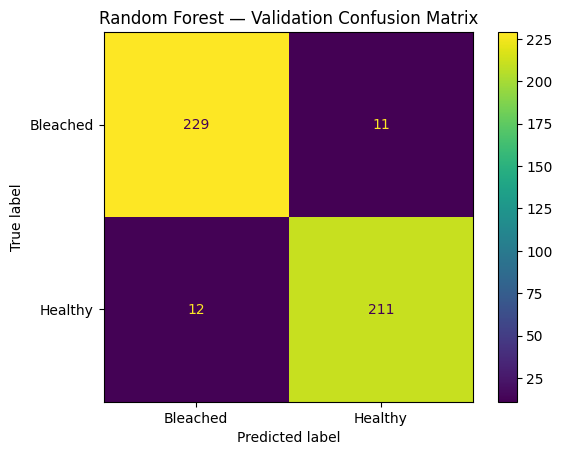

In [ ]:
# Correct validation confusion matrix
cm = confusion_matrix(y_valid, valid_pred, labels=LABELS)
print("Validation confusion matrix (rows = actual, columns = predicted):")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("Random Forest — Validation Confusion Matrix")
plt.show()

Impurity-based feature importance:


,importance
mean_saturation,0.340825
white_pixel_pct,0.187310
entropy,0.081456
mean_brightness,0.079339
mean_lightness,0.074883
lbp_mean,0.063117
glcm_homogeneity,0.062793
glcm_contrast,0.055160
edge_density,0.055115


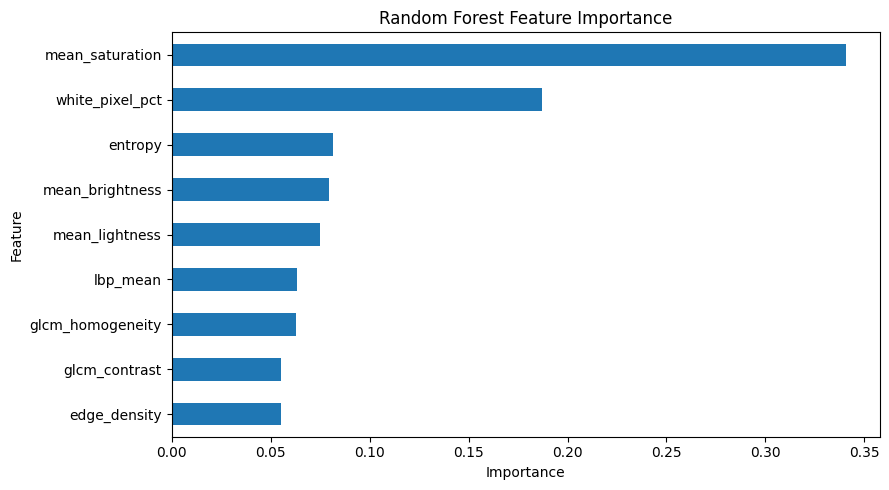

In [ ]:
# Feature importance from the trained Random Forest
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)

print("Impurity-based feature importance:")
display(importance.to_frame("importance"))

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
# Final evaluation on the untouched test set
test_pred = rf.predict(X_test_imp)

print("FINAL TEST RESULTS")
print("Accuracy :", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("\nClassification report:\n")
print(classification_report(y_test, test_pred, labels=LABELS, zero_division=0))

FINAL TEST RESULTS
Accuracy : 0.9611
Precision: 0.9699
Recall   : 0.9556
F1-score : 0.9627

Classification report:

              precision    recall  f1-score   support

    Bleached       0.97      0.96      0.96       135
     Healthy       0.95      0.97      0.96       122

    accuracy                           0.96       257
   macro avg       0.96      0.96      0.96       257
weighted avg       0.96      0.96      0.96       257



Test confusion matrix (rows = actual, columns = predicted):
[[129   6]
 [  4 118]]


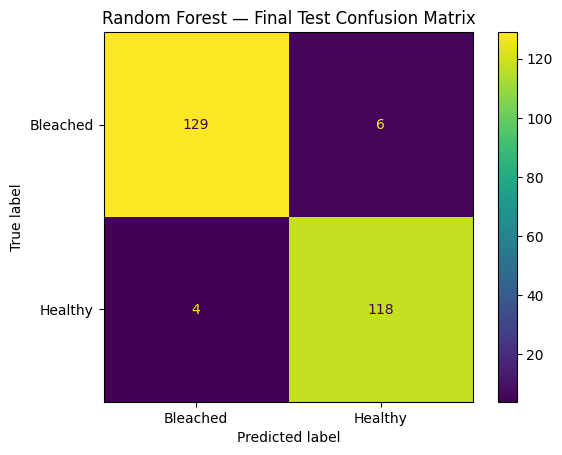

In [ ]:
# Correct final test confusion matrix
cm_test = confusion_matrix(y_test, test_pred, labels=LABELS)
print("Test confusion matrix (rows = actual, columns = predicted):")
print(cm_test)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("Random Forest — Final Test Confusion Matrix")
plt.show()